In [1]:
# NativeNext management setup; original course cells follow with only the explicitly declared16A cell46 homework answer;16B unchanged.
import sys
sys.path.insert(0,'C:\\Users\\[LEARNER_NAME_OMITTED]\\.v\\hi\\20261021T131158-454721e9')
import next_identity as _identity
_identity.write_child_runtime_identity()
import next_adapter as _next
_next.install('C:\\Users\\[LEARNER_NAME_OMITTED]\\.v\\hi\\20261021T131158-454721e9\\source\\HaiLong_Colab_Exercises','C:\\Users\\[LEARNER_NAME_OMITTED]\\.v\\hi\\20261021T131158-454721e9','04_fastai_part2/16A_StyleTransfer.ipynb')


# Google Colab edition

Run the setup cell first, then work from top to bottom. Keep the course ZIP in My Drive. Use a fresh Colab runtime when switching dependency profiles. **Select a GPU runtime before running this notebook.** 

Original numbered course notebook, adapted for Colab. Run in numerical order: later lessons load models trained by earlier lessons. Use the same Drive result folder across sessions. W&B logs stay offline. Full training can exceed a free Colab session; QUICK_RUN does not shorten these original Part 2 experiments.

Source: https://github.com/fastai/course22p2/blob/df9323235bc395b5c2f58a3d08b83761947b9b93/nbs/16A_StyleTransfer.ipynb

In [2]:
# Colab setup. Run this cell before the exercise cells.
from pathlib import Path
import os, sys, zipfile

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
QUICK_RUN = False  #@param {type:"boolean"}
ARCHIVE_PATH = "/content/drive/MyDrive/HaiLong_Colab_Exercises_2026-10-03.zip"  #@param {type:"string"}

try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        if not Path('/content/drive/MyDrive').is_dir():
            drive.mount('/content/drive', timeout_ms=300000)
    COURSE_ROOT = Path('/content/HaiLong_Colab_Exercises')
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        archive = Path(ARCHIVE_PATH)
        if not archive.is_file():
            print('Select HaiLong_Colab_Exercises_2026-10-03.zip from your computer.')
            uploaded = files.upload()
            choices = [Path(n) for n in uploaded if n.endswith('.zip')]
            if len(choices) != 1:
                raise ValueError('Upload exactly one course ZIP file.')
            archive = choices[0]
        with zipfile.ZipFile(archive) as z:
            base = Path('/content').resolve()
            for member in z.infolist():
                target = (base / member.filename).resolve()
                if not target.is_relative_to(base) or not member.filename.startswith('HaiLong_Colab_Exercises/'):
                    raise ValueError('This is not the expected course archive.')
            z.extractall(base)
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        raise FileNotFoundError('The ZIP must contain HaiLong_Colab_Exercises/colab_runtime.py.')
else:
    # Also permits local checks without assuming the current notebook directory.
    COURSE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'colab_runtime.py').is_file()), None)
    if COURSE_ROOT is None:
        raise RuntimeError('Open this notebook in Colab or run it inside the extracted course folder.')

os.environ['COURSE_SMOKE'] = '1' if QUICK_RUN else '0'
os.environ['WANDB_MODE'] = 'offline'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
sys.path.insert(0, str(COURSE_ROOT))
from colab_runtime import setup_course, finish_run
# Filled individually for each notebook by the builder.

COLAB_CONTEXT = setup_course(COURSE_ROOT, '04_fastai_part2', 'part2', '16A_StyleTransfer.ipynb', USE_GOOGLE_DRIVE, install=IN_COLAB)

Exercise folder: C:\Users\[LOCAL_USER]\.v\hi\20261021T131158-454721e9\source\HaiLong_Colab_Exercises\04_fastai_part2
Run mode: FULL EXERCISE
Results: C:\Users\[LOCAL_USER]\.v\hi\20261021T131158-454721e9\source\HaiLong_Colab_Exercises\04_fastai_part2\results


## Full exercise evidence

- Run all exercise cells top to bottom in hosted Colab and preserve their outputs, errors and execution counts.
- Keep QUICK_RUN=False; shortened checks or synthetic replacements for real datasets do not count as full original exercises.
- Preserve plots, models, metrics and run configurations in Drive; a final-cell marker alone is insufficient.
- Retain original datasets, model definitions, training schedules and instructional comparisons.
- Run prerequisite checkpoint-producing notebooks first; do not replace missing weights with untrained models.

- Review the labeled authored objective answers alongside genuine saved exercise outputs; prepared prose does not certify hosted execution, personal reflection or independent learner recall.

This cell describes evidence to collect; it does not certify completion. GPU batch caps preserve dataset coverage and epoch counts, but are documented configuration changes.


In [3]:
MAX_BATCH_SIZE = 32  #@param {type:"integer"}
# Increase on a larger GPU to match the original batch sizes.
assert MAX_BATCH_SIZE > 0

# Setup

In [4]:
import pickle,gzip,math,os,time,shutil,torch,random,timm,torchvision,io,PIL
import fastcore.all as fc,matplotlib as mpl,numpy as np,matplotlib.pyplot as plt
from collections.abc import Mapping
from pathlib import Path
from operator import attrgetter,itemgetter
from functools import partial
from copy import copy
from contextlib import contextmanager

import torchvision.transforms.functional as TF,torch.nn.functional as F
from torchvision import transforms
from torch import tensor,nn,optim
from torch.utils.data import DataLoader,default_collate
from torch.nn import init
from torch.optim import lr_scheduler
from torcheval.metrics import MulticlassAccuracy
from datasets import load_dataset,load_dataset_builder
from fastcore.foundation import L, store_attr

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from miniai.sgd import *
from miniai.resnet import *

In [5]:
# Image URLs for demos. Change as desired.
face_url = "https://images.pexels.com/photos/2690323/pexels-photo-2690323.jpeg?w=256"
spiderweb_url = "https://images.pexels.com/photos/34225/spider-web-with-water-beads-network-dewdrop.jpg?w=256"

# Loading Images

In [6]:
def download_image(url):
    imgb = fc.urlread(url, decode=False) 
    return torchvision.io.decode_image(tensor(list(imgb), dtype=torch.uint8)).float()/255.

In [7]:
content_im = download_image(face_url).to(def_device)
print('content_im.shape:', content_im.shape)
show_image(content_im);

content_im.shape: torch.Size([3, 256, 256])


In [8]:
content_im.min(),content_im.max() # Check bounds

(tensor(0., device='cuda:0'), tensor(1., device='cuda:0'))

# Optimizing Images

In [9]:
class LengthDataset():
    def __init__(self, length=1): self.length=length
    def __len__(self): return self.length
    def __getitem__(self, idx): return 0,0

def get_dummy_dls(length=100):
    return DataLoaders(DataLoader(LengthDataset(length), batch_size=1), # Train
                       DataLoader(LengthDataset(1), batch_size=1))      # Valid (length 1)

In [10]:
class TensorModel(nn.Module):
    def __init__(self, t):
        super().__init__()
        self.t = nn.Parameter(t.clone())
    def forward(self, x=0): return self.t

In [11]:
model = TensorModel(torch.rand_like(content_im))
show_image(model());

In [12]:
[p.shape for p in model.parameters()]

[torch.Size([3, 256, 256])]

In [13]:
class ImageOptCB(TrainCB):
    def predict(self, learn): learn.preds = learn.model()
    def get_loss(self, learn): learn.loss = learn.loss_func(learn.preds)

In [14]:
def loss_fn_mse(im):
    return F.mse_loss(im, content_im)

model = TensorModel(torch.rand_like(content_im))
cbs = [ImageOptCB(), ProgressCB(), MetricsCB(), DeviceCB()]
learn = Learner(model, get_dummy_dls(100), loss_fn_mse, 
                lr=1e-2, cbs=cbs, opt_func=torch.optim.Adam)
learn.fit(1)

Storage check (before_fit): artifacts 0.003 GB; configured budget 80.000 GB; additional estimate 0.043 GB; runtime free 484.119 GB. Budget is not Drive quota.
Storage check (checkpoint_write): artifacts 0.003 GB; configured budget 80.000 GB; additional estimate 0.009 GB; runtime free 484.119 GB. Budget is not Drive quota.


loss,epoch,train
0.042,0,train
0.001,0,eval


Storage check (checkpoint_write): artifacts 0.005 GB; configured budget 80.000 GB; additional estimate 0.011 GB; runtime free 484.116 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 0.007 GB; configured budget 80.000 GB; additional estimate 0.011 GB; runtime free 484.115 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 0.013 GB; configured budget 80.000 GB; additional estimate 0.009 GB; runtime free 484.108 GB. Budget is not Drive quota.


In [15]:
# Result (left) vs target image (right):
show_images([learn.model().clip(0, 1), content_im]);

## Viewing progress

It would be great if we could see what is happening over time. You could save individual images and turn them into a video, but for quick feedback we can also log images every few iterations and display them in a grid in `after_fit`:

In [16]:
class ImageLogCB(Callback):
    order = ProgressCB.order + 1
    def __init__(self, log_every=10): store_attr(); self.images=[]; self.i=0
    def after_batch(self, learn): 
        if self.i%self.log_every == 0: self.images.append(to_cpu(learn.preds.clip(0, 1)))
        self.i += 1
    def after_fit(self, learn): show_images(self.images)

In [17]:
model = TensorModel(torch.rand_like(content_im))
learn = Learner(model, get_dummy_dls(150), loss_fn_mse, 
                lr=1e-2, cbs=cbs, opt_func=torch.optim.Adam)
learn.fit(1, cbs=[ImageLogCB(30)])

Storage check (before_fit): artifacts 0.012 GB; configured budget 80.000 GB; additional estimate 0.043 GB; runtime free 484.113 GB. Budget is not Drive quota.
Storage check (checkpoint_write): artifacts 0.012 GB; configured budget 80.000 GB; additional estimate 0.009 GB; runtime free 484.113 GB. Budget is not Drive quota.


loss,epoch,train
0.028,0,train
0.000,0,eval


Storage check (checkpoint_write): artifacts 0.014 GB; configured budget 80.000 GB; additional estimate 0.011 GB; runtime free 484.110 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 0.016 GB; configured budget 80.000 GB; additional estimate 0.011 GB; runtime free 484.109 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 0.028 GB; configured budget 80.000 GB; additional estimate 0.009 GB; runtime free 484.096 GB. Budget is not Drive quota.


## Getting Features from VGG16

We're going to peek inside a small CNN and extract the outputs of different layers.

### Load VGG network

![vgg diag](https://neurohive.io/wp-content/uploads/2018/11/vgg16-1-e1542731207177.png)

In [18]:
print(timm.list_models('*vgg*'))

['repvgg_a0', 'repvgg_a1', 'repvgg_a2', 'repvgg_b0', 'repvgg_b1', 'repvgg_b1g4', 'repvgg_b2', 'repvgg_b2g4', 'repvgg_b3', 'repvgg_b3g4', 'repvgg_d2se', 'vgg11', 'vgg11_bn', 'vgg13', 'vgg13_bn', 'vgg16', 'vgg16_bn', 'vgg19', 'vgg19_bn']


In [19]:
vgg16 = timm.create_model('vgg16', pretrained=True).to(def_device).features

In [20]:
# vgg16

### Normalize Images

This model expacts images normalized with the same stats as those used during training, which in this case requires the stats of the ImageNet dataset. Previously we were working with single-channel images, and so normalizing was pretty straightforward. With three channels, we need to think a bit more about shapes and boradcasting rules:

In [21]:
imagenet_mean = tensor([0.485, 0.456, 0.406])
imagenet_std = tensor([0.229, 0.224, 0.225])

In [22]:
# Try 1 (won't work):
# (content_im - imagenet_mean) / imagenet_std

In [23]:
imagenet_mean.shape

torch.Size([3])

In [24]:
content_im.shape

torch.Size([3, 256, 256])

In [25]:
imagenet_mean[:,None,None].shape

torch.Size([3, 1, 1])

In [26]:
# Try 2:
def normalize(im):
    imagenet_mean = tensor([0.485, 0.456, 0.406])[:,None,None].to(im.device)
    imagenet_std = tensor([0.229, 0.224, 0.225])[:,None,None].to(im.device)
    return (im - imagenet_mean) / imagenet_std

In [27]:
normalize(content_im).min(), normalize(content_im).max()

(tensor(-2.1179, device='cuda:0'), tensor(2.6400, device='cuda:0'))

In [28]:
normalize(content_im).mean(dim=(1, 2))

tensor([-0.9799, -0.9721, -0.4301], device='cuda:0')

In [29]:
# And with torchvision transforms:
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

In [30]:
normalize(content_im).min(), normalize(content_im).max()

(tensor(-2.1179, device='cuda:0'), tensor(2.6400, device='cuda:0'))

### Get intermediate representations, take 1:

We want to feed some data through the network, storing thr outputs of different layers. Here's one way to do this:

In [31]:
def calc_features(imgs, target_layers=(18, 25)): 
    x = normalize(imgs)
    feats = []
    for i, layer in enumerate(vgg16[:max(target_layers)+1]):
        x = layer(x)
        if i in target_layers:
            feats.append(x.clone())
    return feats

In [32]:
# Testing it out to see the shapes of the resulting feature maps:
feats = calc_features(content_im)
[f.shape for f in feats]

[torch.Size([512, 32, 32]), torch.Size([512, 16, 16])]

In [33]:
"""Proposed 16A hook homework; no model construction, download or execution.

The original VGG16 feature Sequential has distinct top-level layer instances.
Forward hooks fire in that model's traversal order, so target order/duplicates
are handled just like the original membership test. This does not promise the
same semantics for a custom graph that reuses a module at multiple positions.
"""


def calc_features_with_hooks(imgs, target_layers=(18, 25), *, model, normalize):
    """Return differentiable activation copies from the original model prefix.

    Clone inside the hook, before a later in-place layer can alter the output.
    Do not detach or use no_grad: style-transfer input gradients must survive.
    The caller supplies the original VGG16 features and normalization callable.
    """
    x = normalize(imgs)
    features = []
    handles = []
    prefix = model[:max(target_layers) + 1]

    def capture(_module, _inputs, output):
        features.append(output.clone())

    try:
        for index, layer in enumerate(prefix):
            if index in target_layers:
                handles.append(layer.register_forward_hook(capture))
        prefix(x)
    finally:
        for handle in handles:
            handle.remove()

    return features


def calc_features(imgs, target_layers=(18, 25)):
    return calc_features_with_hooks(
        imgs, target_layers, model=vgg16, normalize=normalize
    )


### What's the point?

You may remember us looking at https://distill.pub/2017/feature-visualization/ and talking about how deep CNNs 'learn' to classify images. Early layers tend to capture gradients and textures, while later layers tend towards more complex types of feature. We're going to exploit this hierarchy for artistic purposes, but being able to choose what kind of feature you'd like to use when comparing images has a number of other useful applications. 

# Optimizing an Image with Content Loss

To start with, let's try optimizing an image by comparing it's features (from two later layers) with those from the target image. If our theory is right, we should see the structure of the target emerge from the noise without necessarily seeing a perfect re-production of the target like we did in the previous MSE loss example.

In [34]:
class ContentLossToTarget():
    def __init__(self, target_im, target_layers=(18, 25)):
        fc.store_attr()
        with torch.no_grad():
            self.target_features = calc_features(target_im, target_layers)
    def __call__(self, input_im): 
        return sum((f1-f2).pow(2).mean() for f1, f2 in 
               zip(calc_features(input_im, self.target_layers), self.target_features))

In [35]:
loss_function_perceptual = ContentLossToTarget(content_im)
model = TensorModel(torch.rand_like(content_im))
learn = Learner(model, get_dummy_dls(150), loss_function_perceptual, 
                lr=1e-2, cbs=cbs, opt_func=torch.optim.Adam)
learn.fit(1, cbs=[ImageLogCB(log_every=30)])

Storage check (before_fit): artifacts 0.050 GB; configured budget 80.000 GB; additional estimate 0.043 GB; runtime free 484.069 GB. Budget is not Drive quota.
Storage check (checkpoint_write): artifacts 0.050 GB; configured budget 80.000 GB; additional estimate 0.009 GB; runtime free 484.069 GB. Budget is not Drive quota.


loss,epoch,train
5.026,0,train
1.526,0,eval


Storage check (checkpoint_write): artifacts 0.112 GB; configured budget 80.000 GB; additional estimate 0.011 GB; runtime free 484.008 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 0.113 GB; configured budget 80.000 GB; additional estimate 0.011 GB; runtime free 484.006 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 0.226 GB; configured budget 80.000 GB; additional estimate 0.009 GB; runtime free 483.894 GB. Budget is not Drive quota.


**Choosing the layers determines the kind of features that are important:**

In [36]:
loss_function_perceptual = ContentLossToTarget(content_im, target_layers=(1, 6))
model = TensorModel(torch.rand_like(content_im))
learn = Learner(model, get_dummy_dls(150), loss_function_perceptual, 
                lr=1e-2, cbs=cbs, opt_func=torch.optim.Adam)
learn.fit(1, cbs=[ImageLogCB(log_every=30)])

Storage check (before_fit): artifacts 0.224 GB; configured budget 80.000 GB; additional estimate 0.043 GB; runtime free 483.895 GB. Budget is not Drive quota.
Storage check (checkpoint_write): artifacts 0.224 GB; configured budget 80.000 GB; additional estimate 0.009 GB; runtime free 483.895 GB. Budget is not Drive quota.


loss,epoch,train
2.349,0,train
0.364,0,eval


Storage check (checkpoint_write): artifacts 0.325 GB; configured budget 80.000 GB; additional estimate 0.011 GB; runtime free 483.795 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 0.327 GB; configured budget 80.000 GB; additional estimate 0.011 GB; runtime free 483.793 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 0.440 GB; configured budget 80.000 GB; additional estimate 0.009 GB; runtime free 483.680 GB. Budget is not Drive quota.


# Style Loss with Gram Matrix

So, we know how to extract feature maps. The next thing we'd like to do is find a way to capture the **style** of an input image, based on those early layers and the kinds of textural feature that they learn. Unfortunately, we can't just compare the feature maps from some early layers since these 'maps' encode information spatially - which we don't want!

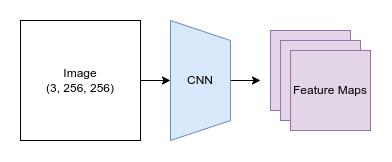

So, we need a way to measure what **kinds** of style features are present, and ideally which kinds occur together, without worrying about **where** these features occur in the image. 

Enter something called the Gram Matrix. The idea here is that we'll measure the **correlation** between features. Given a feature map with `f` features in an `h` x `w` grid, we'll flatten out the spatial component and then for every feature we'll take the dot product of that row with itself, giving an `f` x `f` matrix as the result. Each entry in this matrix quantifies how correlated the relevant pair of features are and how frequently they occur - exactly what we want. In this diagram each feature is represented as a colored dot.

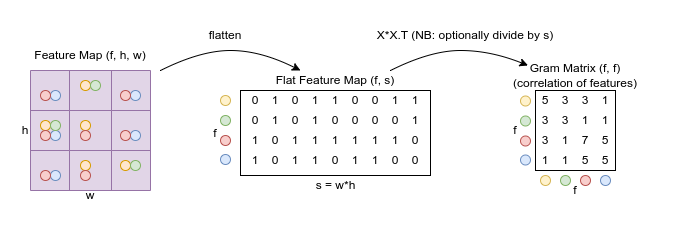

Re-creating the diagram operations in code:

In [37]:
t = tensor([[0, 1, 0, 1, 1, 0, 0, 1, 1],
            [0, 1, 0, 1, 0, 0, 0, 0, 1],
            [1, 0, 1, 1, 1, 1, 1, 1, 0],
            [1, 0, 1, 1, 0, 1, 1, 0, 0]])

In [38]:
torch.einsum('fs, gs -> fg', t, t)

tensor([[5, 3, 3, 1],
        [3, 3, 1, 1],
        [3, 1, 7, 5],
        [1, 1, 5, 5]])

In [39]:
t.matmul(t.T) # Alternate approach

tensor([[5, 3, 3, 1],
        [3, 3, 1, 1],
        [3, 1, 7, 5],
        [1, 1, 5, 5]])

### Trying it out

In [40]:
style_im = download_image(spiderweb_url).to(def_device)
show_image(style_im);

In [41]:
def calc_grams(img, target_layers=(1, 6, 11, 18, 25)):
    return L(torch.einsum('chw, dhw -> cd', x, x) / (x.shape[-2]*x.shape[-1]) # 'bchw, bdhw -> bcd' if batched
            for x in calc_features(img, target_layers))

In [42]:
style_grams = calc_grams(style_im)

In [43]:
[g.shape for g in style_grams] # The gram matrices for features from different layers

[torch.Size([64, 64]),
 torch.Size([128, 128]),
 torch.Size([256, 256]),
 torch.Size([512, 512]),
 torch.Size([512, 512])]

In [44]:
style_grams.attrgot('shape') # The magic of fastcore's L

[torch.Size([64, 64]), torch.Size([128, 128]), torch.Size([256, 256]), torch.Size([512, 512]), torch.Size([512, 512])]

In [45]:
class StyleLossToTarget():
    def __init__(self, target_im, target_layers=(1, 6, 11, 18, 25)):
        fc.store_attr()
        with torch.no_grad(): self.target_grams = calc_grams(target_im, target_layers)
    def __call__(self, input_im): 
        return sum((f1-f2).pow(2).mean() for f1, f2 in 
               zip(calc_grams(input_im, self.target_layers), self.target_grams))

In [46]:
style_loss = StyleLossToTarget(style_im)

In [47]:
style_loss(content_im)

tensor(285.1028, device='cuda:0', grad_fn=<AddBackward0>)

## Style Transfer

In [48]:
model = TensorModel(content_im) # Start from content image
style_loss = StyleLossToTarget(style_im)
content_loss = ContentLossToTarget(content_im)
def combined_loss(x):
    return style_loss(x) + content_loss(x)
learn = Learner(model, get_dummy_dls(150), combined_loss, lr=1e-2, cbs=cbs, opt_func=torch.optim.Adam)
learn.fit(1, cbs=[ImageLogCB(30)])

Storage check (before_fit): artifacts 0.475 GB; configured budget 80.000 GB; additional estimate 0.043 GB; runtime free 483.645 GB. Budget is not Drive quota.
Storage check (checkpoint_write): artifacts 0.475 GB; configured budget 80.000 GB; additional estimate 0.009 GB; runtime free 483.645 GB. Budget is not Drive quota.


loss,epoch,train
53.717,0,train
35.559,0,eval


Storage check (checkpoint_write): artifacts 0.576 GB; configured budget 80.000 GB; additional estimate 0.011 GB; runtime free 483.542 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 0.578 GB; configured budget 80.000 GB; additional estimate 0.011 GB; runtime free 483.540 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 0.692 GB; configured budget 80.000 GB; additional estimate 0.009 GB; runtime free 483.426 GB. Budget is not Drive quota.


In [49]:
show_image(learn.model().clip(0, 1)); # View the final result

And trying with random starting image, weighting the style loss lower, using different layers:

In [50]:
model = TensorModel(torch.rand_like(content_im))
style_loss = StyleLossToTarget(style_im)
content_loss = ContentLossToTarget(content_im, target_layers=(6, 18, 25))
def combined_loss(x):
    return style_loss(x) * 0.2 + content_loss(x)
learn = Learner(model, get_dummy_dls(300), combined_loss, lr=5e-2, cbs=cbs, opt_func=torch.optim.Adam)
learn.fit(1, cbs=[ImageLogCB(60)])

Storage check (before_fit): artifacts 0.697 GB; configured budget 80.000 GB; additional estimate 0.043 GB; runtime free 483.422 GB. Budget is not Drive quota.
Storage check (checkpoint_write): artifacts 0.697 GB; configured budget 80.000 GB; additional estimate 0.009 GB; runtime free 483.422 GB. Budget is not Drive quota.


loss,epoch,train
36.013,0,train
28.003,0,eval


Storage check (checkpoint_write): artifacts 0.799 GB; configured budget 80.000 GB; additional estimate 0.011 GB; runtime free 482.640 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 0.800 GB; configured budget 80.000 GB; additional estimate 0.011 GB; runtime free 482.637 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 0.916 GB; configured budget 80.000 GB; additional estimate 0.009 GB; runtime free 482.230 GB. Budget is not Drive quota.


## For Comparison: non-miniai version

In [51]:
# The image to be optimized
im = torch.rand(3, 256, 256).to(def_device)
im.requires_grad = True

# Set up the optimizer
opt = torch.optim.Adam([im], lr=5e-2)

# Define the loss function
style_loss = StyleLossToTarget(style_im)
content_loss = ContentLossToTarget(content_im, target_layers=[6, 18, 25])
def combined_loss(x):
    return style_loss(x) * 0.2 + content_loss(x)

# Optimization loop
for i in range(300):
    loss = combined_loss(im)
    loss.backward()
    opt.step()
    opt.zero_grad()
    
# Show the result
show_image(im.clip(0, 1));

What do you think are some pros and cons? How would this look once we start displaying progress, testing different configurations and so on?

## Authored comparison: Learner and a direct image-optimization loop

The direct loop makes the particular task visible: a single image tensor is the parameter, Adam updates it, and style/content losses determine its gradients. In the preserved example it uses 300 updates, learning rate 0.05, content layers 6/18/25 and a style-loss multiplier of 0.2. It is compact and easy to inspect or customize. It also requires explicit code for image snapshots, progress, device management, logging, scheduling, checkpointing and configuration records as those needs grow.

The miniai implementation reuses Learner events and callbacks for those responsibilities. `ImageLogCB` stores intermediate images at its configured interval, while the other callbacks provide training-loop behavior and progress. The same loss and optimization logic can be reused across configurations without duplicating the loop. The tradeoffs are extra abstractions and event order to understand; a dummy data loader represents repeated image updates even though this task is not conventional supervised minibatch training. Debugging a callback interaction can be less direct than inspecting the short loop.

For a useful controlled comparison, record the image/model version, initial optimized image or seed, image resolution, target layers, loss weights, optimizer, rate, step count and snapshot interval. Hold those fixed when comparing implementations, then vary a specified configuration deliberately and preserve loss traces and images. Both preserved examples use fresh random starts, so their differing final pictures alone cannot establish a framework advantage. Progress displays and callback reuse are implementation conveniences, not evidence of better style-transfer quality. This is an objective design analysis; your own preference remains yours to record.

[Pinned source and original final prompt, cell 77](https://github.com/fastai/course22p2/blob/df9323235bc395b5c2f58a3d08b83761947b9b93/nbs/16A_StyleTransfer.ipynb).


Save your outputs

Run the following cell after finishing. Choose **File > Save** in Colab to preserve your code and displayed results. Files in `results/` and `models/` persist in Drive when enabled.

In [52]:
finish_run(COLAB_CONTEXT)

Saved run settings. Save the notebook in Colab to keep its cell outputs.


In [53]:
# NativeNext independent numerical probe.
_next.probe(globals())


__HAILONG_NATIVE_NEXT_FULL_EVIDENCE__{"full_course_probe_verified": true, "contract": {"passed": true, "fits": 6, "fit_updates": 1000, "manual_updates": 300, "total_updates": 1300, "validation_forwards": 6}, "numerical_reference_reports": [{"cell": 17, "original_validation_loss": 0.0013710757484659553, "CPU_reference_loss": 0.0013710757484659553, "relative_tolerance": 0.0005, "absolute_tolerance": 0.0001}, {"cell": 22, "original_validation_loss": 6.0507045418489724e-05, "CPU_reference_loss": 6.050703814253211e-05, "relative_tolerance": 0.0005, "absolute_tolerance": 0.0001}, {"cell": 52, "original_validation_loss": 1.5259642601013184, "CPU_reference_loss": 1.525964379310608, "relative_tolerance": 0.0005, "absolute_tolerance": 0.0001}, {"cell": 54, "original_validation_loss": 0.3638952076435089, "CPU_reference_loss": 0.3638952374458313, "relative_tolerance": 0.0005, "absolute_tolerance": 0.0001}, {"cell": 74, "original_validation_loss": 35.559104919433594, "CPU_reference_loss": 35.559104

{'full_course_probe_verified': True,
 'contract': {'passed': True,
  'fits': 6,
  'fit_updates': 1000,
  'manual_updates': 300,
  'total_updates': 1300,
  'validation_forwards': 6},
 'numerical_reference_reports': [{'cell': 17,
   'original_validation_loss': 0.0013710757484659553,
   'CPU_reference_loss': 0.0013710757484659553,
   'relative_tolerance': 0.0005,
   'absolute_tolerance': 0.0001},
  {'cell': 22,
   'original_validation_loss': 6.0507045418489724e-05,
   'CPU_reference_loss': 6.050703814253211e-05,
   'relative_tolerance': 0.0005,
   'absolute_tolerance': 0.0001},
  {'cell': 52,
   'original_validation_loss': 1.5259642601013184,
   'CPU_reference_loss': 1.525964379310608,
   'relative_tolerance': 0.0005,
   'absolute_tolerance': 0.0001},
  {'cell': 54,
   'original_validation_loss': 0.3638952076435089,
   'CPU_reference_loss': 0.3638952374458313,
   'relative_tolerance': 0.0005,
   'absolute_tolerance': 0.0001},
  {'cell': 74,
   'original_validation_loss': 35.55910491943359